# Q3 · Steps 2–3 — Baseline models with scikit-learn
Logistic Regression (the main baseline) and a Random Forest (a stronger reference), both inside a pipeline with the preprocessing.

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from lab_utils import save_json, load_json, savefig
import q3_common as q3
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

df = q3.load_adult(ROOT / "data" / "q3_adult")
X_train, X_test, y_train, y_test = q3.split_data(df)
print("train:", X_train.shape, "test:", X_test.shape, "| positive rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

train: (26048, 12) test: (6513, 12) | positive rate train/test: 0.241 0.241


## Train the baselines

In [4]:
models = {
  "Logistic Regression (baseline)": LogisticRegression(max_iter=2000, random_state=q3.RANDOM_STATE),
  "Random Forest (reference)":      RandomForestClassifier(n_estimators=200, random_state=q3.RANDOM_STATE, n_jobs=-1),
}
fitted, rows = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", q3.build_preprocessor()), ("clf", clf)])
    t = time.perf_counter(); pipe.fit(X_train, y_train); fit_t = time.perf_counter() - t
    m = q3.compute_metrics(pipe, X_test, y_test)
    rows.append({"model": name, **m, "train_time_s": fit_t, "inference_ms_per_row": q3.time_inference(pipe, X_test),
                 **q3.describe_complexity(pipe)})
    fitted[name] = pipe
base_df = pd.DataFrame(rows); display(base_df.round(4))

,model,accuracy,precision,recall,f1,roc_auc,train_time_s,inference_ms_per_row,final_estimator,size
0,Logistic Regression (baseline),0.8569,0.7439,0.6186,0.6755,0.9088,1.7491,0.0106,LogisticRegression,106 coefficients
1,Random Forest (reference),0.8537,0.7296,0.6231,0.6722,0.8961,5.2128,0.0397,RandomForestClassifier,"200 trees, 1824014 nodes"


## 5-fold cross-validation of the main baseline (ROC-AUC)

In [5]:
lr_name = "Logistic Regression (baseline)"
cv = cross_val_score(Pipeline([("prep", q3.build_preprocessor()), ("clf", models[lr_name])]), X_train, y_train,
                     cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="roc_auc", n_jobs=1)
print(f"CV ROC-AUC = {cv.mean():.4f} ± {cv.std():.4f}")

CV ROC-AUC = 0.9153 ± 0.0019


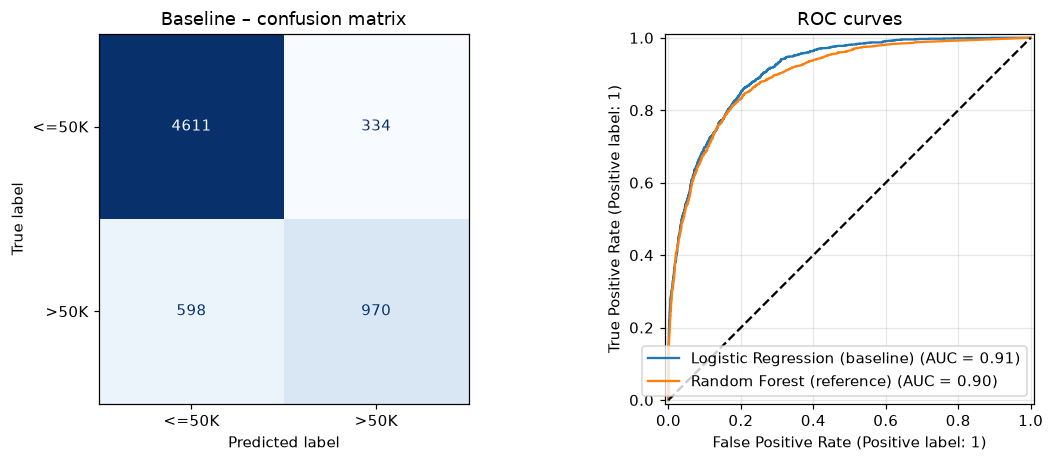

              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4945
        >50K       0.74      0.62      0.68      1568

    accuracy                           0.86      6513
   macro avg       0.81      0.78      0.79      6513
weighted avg       0.85      0.86      0.85      6513



In [6]:
lr = fitted[lr_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test, display_labels=["<=50K", ">50K"], cmap="Blues", ax=axes[0], colorbar=False); axes[0].grid(False); axes[0].set_title("Baseline – confusion matrix")
for n, p in fitted.items(): RocCurveDisplay.from_estimator(p, X_test, y_test, ax=axes[1], name=n)
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curves")
plt.tight_layout(); savefig(fig, "q3", "baseline_cm_roc"); plt.show()
print(classification_report(y_test, lr.predict(X_test), target_names=["<=50K", ">50K"]))

### Which metrics and why?
* **Accuracy** – easy to read but misleading with 76 % / 24 % classes (predicting "<=50K" for everybody already gives ~76 %).
* **Precision / Recall / F1** of the positive class (>50K) – show how well the minority class is found.
* **ROC-AUC** – threshold-independent ranking quality; used as the main model-selection metric.

In [ ]:
joblib.dump(fitted[lr_name], ROOT / "models" / "baseline_model.joblib")
joblib.dump(fitted["Random Forest (reference)"], ROOT / "models" / "baseline_rf_model.joblib")
save_json({"table": base_df.to_dict("records"), "cv_roc_auc_mean": float(cv.mean()), "cv_roc_auc_std": float(cv.std()),
           "main_baseline": lr_name, "n_train": int(len(y_train)), "n_test": int(len(y_test))},
          ROOT / "results" / "q3" / "baseline_results.json")
print("Saved models/baseline_model.joblib and results/q3/baseline_results.json ✔")

Saved models/baseline_model.joblib and results/q3/baseline_results.json ✔


: 